<a href="https://colab.research.google.com/github/RainanCoelho/Projeto-Analise-Exploratoria-Grupo8-Gestao_de_Vendedores-Parceiros/blob/main/Dataset_order_items_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**FRENTE 1**

PARTE 1: Carga e preparação da Base do dataset escolhido

In [1]:
import pandas as pd
import numpy as np

URL = "https://raw.githubusercontent.com/RainanCoelho/Projeto-Analise-Exploratoria-Grupo8-Gestao_de_Vendedores-Parceiros/refs/heads/main/olist_order_items_dataset.csv"
df_oid = pd.read_csv(URL)
df_oid.columns = ["order_id","order_item_id","product_id","seller_id","shipping_limit_date","price","freight_value"]
df_oid.head(20)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40


PARTE 2: CONHECIMENTO DOS DADOS

In [2]:
df_oid.shape #Mostra no console a quantidade de linhas e colunas do dataset
df_oid.info() #Mostra o tipo e a quantidade de valores não nulos
df_oid.describe() #Mostra a estatística das tabelas, como média, valor máximo, mínimo, valores interquartis e mais
df_oid.dtypes #Mostra os tipos dos valores de cada coluna

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


,0
order_id,object
order_item_id,int64
product_id,object
seller_id,object
shipping_limit_date,object
price,float64
freight_value,float64


Parte 3: Correção de Tipos

In [3]:
#Primeiro Comando da Pipeline
#Mudar o tipo dos valores de Object para Date
def correção_tipo_slt(df_oid):
  df_oid["shipping_limit_date"] = pd.to_datetime(df_oid["shipping_limit_date"], errors="coerce")
  return df_oid
correção_tipo_slt(df_oid)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72


**Explicação**: O pandas reconhece a tabela "shipping_limit_date" como "Object", mas o correto seria uma leitura da mesma como "Date", por isso a alteração

Parte 4: Verificação de Valores

In [4]:
df_oid.isnull().sum() #Verifica se a coluna possuia algum valor nulo

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


**Explicação**: Não foi visto nenhum valor nulo na coluna


In [5]:
df_oid.duplicated().sum() #Verifica se na tabela existe alguma linha duplicada

np.int64(0)

**Explicação**: Não foi visto nenhuma linha duplicada

In [6]:
(df_oid["price"] <=0).sum() #Verifica se existe algum valor da coluna "price" onde o valor é menor que 0

np.int64(0)

**Explicação**: Não foi visto nenhum valor abaixo de 0

In [7]:
(df_oid["freight_value"] < 0).sum() #Soma quantos fretes estão com o valor menor que 0

np.int64(0)

**Explicação**: Não foi visto nenhum valor abaixo de 0

In [8]:
df_oid["shipping_limit_date"].min(), df_oid["shipping_limit_date"].max() #Mostra os valores máximos e mínimos

(Timestamp('2016-09-19 00:15:34'), Timestamp('2020-04-09 22:35:08'))

**Explicação**: Valor mínimo está no prazo do dito no kaggle 2016-2018, mas o valor máximo ultrapassa

In [9]:
(df_oid["shipping_limit_date"].dt.year > 2018).sum() #Conta quantos valores estão acima de 2018 na tebela

np.int64(4)

**Explicação**: Conta a quantidade de valores acima do valor máximo dito no Kaggle(2018)

In [10]:
(df_oid["shipping_limit_date"].dt.year < 2016).sum() #Conta quantos valores estão abaixo de 2016

np.int64(0)

**Explicação**: Conta quantos valores estão abaixo do mínimo dito no Kaggle(2016)

In [11]:
#Verifica se tem ID duplicado ou vazio na coluna "order_id"
df_oid["order_id"].duplicated().sum()
df_oid["order_id"].isnull().sum()

np.int64(0)

**Explicação**: Nenhum ID está duplicado ou vazio

In [12]:
#Verifica se tem ID duplicado ou vazio na coluna "product_id"
df_oid["product_id"].duplicated().sum()
df_oid["product_id"].isnull().sum()

np.int64(0)

**Explicação**: Nenhum ID está duplicado ou vazio

In [13]:
#Verifica se tem ID duplicado ou vazio na coluna "seller_id"
df_oid["seller_id"].duplicated().sum()
df_oid["seller_id"].isnull().sum()

np.int64(0)

**Explicação**: Nenhum ID está duplicado ou vazio

Parte 5: Tratamento de Valores

In [14]:
#Segundo comando da pipeline
#Remoção de datas inválidas
def remover_valores_incoerentes(df_oid):
  return df_oid[df_oid["shipping_limit_date"].dt.year <= 2018]

print("Antes:", len(df_oid))
df_oid = remover_valores_incoerentes(df_oid)
print("Depois:", len(df_oid))

Antes: 112650
Depois: 112646


**Explicação**: No site da Kaggle, foi dito que os dados foram retirados entre os períodos de 2016 a 2018, porém, na tabela existe valores que estão datados após o valor máximo de 2018, então, esses determinados valores foram retirados do sistema

In [15]:
#segundo comando da pipeline
def verificar_outliers(df_oid):
  for coluna in ["price", "freight_value"]:
      q1 = df_oid[coluna].quantile(0.25)
      q3 = df_oid[coluna].quantile(0.75)
      iqr = q3 - q1
      limite_inf = q1 - 1.5 * iqr
      limite_sup = q3 + 1.5 * iqr
      print("----------------------------------------------------------------------")
      print("limite superior da coluna ",coluna,"=", limite_sup)
      print("limite inferior da coluna ",coluna,"=", limite_inf)
      outlier = df_oid[(df_oid[coluna] > limite_sup) | (df_oid[coluna] < limite_inf)]
      display(outlier.head(5))

verificar_outliers(df_oid)



----------------------------------------------------------------------
limite superior da coluna  price = 277.4
limite inferior da coluna  price = -102.6


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.0,70.75
16,0009c9a17f916a706d71784483a5d643,1,3f27ac8e699df3d300ec4a5d8c5cf0b2,fcb5ace8bcc92f75707dc0f01a27d269,2018-05-02 09:31:53,639.0,11.34
26,0011d82c4b53e22e84023405fb467e57,1,c389f712c4b4510bc997cee93e8b1a28,bfd27a966d91cfaafdb25d076585f0da,2018-01-29 21:51:25,289.0,26.33
30,00137e170939bba5a3134e2386413108,1,672e757f331900b9deea127a2a7b79fd,e59aa562b9f8076dd550fcddf0e73491,2017-11-30 06:30:55,397.0,24.65
39,0017afd5076e074a48f1f1a4c7bac9c5,1,fe59a1e006df3ac42bf0ceb876d70969,25c5c91f63607446a97b143d2d535d31,2017-04-24 22:25:19,809.1,44.29


----------------------------------------------------------------------
limite superior da coluna  freight_value = 33.254999999999995
limite inferior da coluna  freight_value = 0.9750000000000032


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75
22,000f25f4d72195062c040b12dce9a18a,1,1c05e0964302b6cf68ca0d15f326c6ba,7c67e1448b00f6e969d365cea6b010ab,2018-03-21 11:10:11,119.99,44.40
39,0017afd5076e074a48f1f1a4c7bac9c5,1,fe59a1e006df3ac42bf0ceb876d70969,25c5c91f63607446a97b143d2d535d31,2017-04-24 22:25:19,809.10,44.29
59,00254baeb6c932b0a8aeead91fbd02b5,1,18901878788fec7ddc55e64d1ace8187,e8b4225284fbb02d16f200513f1f395d,2018-05-14 22:14:46,149.90,43.11
73,002b430ff89b3a24c31a1170acbbedea,1,cc47c0863559499f01b4cad750929d10,7a67c85e85bb2ce8582c35f2203ad736,2017-06-26 22:10:14,199.99,65.56


In [16]:
#Verificar a correlação de cada uma
df_oid["freight_value"].corr(df_oid["price"])

np.float64(0.41423399934601124)

**Explicação**: Na verificação de outlier, foi verificados os valores que correspondem aos valores de interquartis, e com isso, foi verificado quais tabelas tinham os valores que eram acima dos limites superiores e inferiores de cada coluna tratado no laço "for", e com isso, foi decidido que os valores de outlier seriam mantidos no sistema, já que foi visto que a correlação dos valores estão entre 0.4, ou seja, é moderada, e com isso, há uma relação entre valor alto no frete e valor alto no preço. Além disso, uma exclusão dos valores faria com que houvesse uma distorção na análise, já que em muitos casos um preço alto possui um frete alto, e isso, deixaria a análise incompleta.

**FRENTE 2**

PARTE 6: CRIAÇÃO DE NOVOS ATRIBUTOS (FEATURE ENGINEERING)

In [17]:
def criar_features_order_items(df):
    out = df.copy()

    # Soma o preço do produto com o valor do frete
    out["valor_total_item"] = out["price"] + out["freight_value"]

    # Calcula quanto o frete representa em relação ao preço (evitando divisão por zero)
    out["proporcao_frete_preco"] = np.where(
        out["price"] > 0,
        out["freight_value"] / out["price"],
        np.nan,
    )

    # Agregações por vendedor: total de itens vendidos e preço médio dos produtos
    out["qtd_itens_vendedor"] = out.groupby("seller_id")["order_id"].transform("count")
    out["ticket_medio_vendedor"] = out.groupby("seller_id")["price"].transform("mean")

    # Flag binária (1/0) indicando se o item faz parte de um pedido com mais de 1 item
    out["flag_multiplos_itens"] = (out["order_item_id"] > 1).astype(int)

    return out


# Gera o novo DataFrame com as features criadas
df_oid_f2 = criar_features_order_items(df_oid)

novas_cols = [
    "valor_total_item",
    "proporcao_frete_preco",
    "qtd_itens_vendedor",
    "ticket_medio_vendedor",
    "flag_multiplos_itens",
]

# Exibe estatísticas descritivas e contagem de nulos das novas colunas
print(df_oid_f2[novas_cols].describe())
print("\nNulos nas novas colunas:")
print(df_oid_f2[novas_cols].isna().sum())

       valor_total_item  proporcao_frete_preco  qtd_itens_vendedor  \
count     112646.000000          112646.000000       112646.000000   
mean         140.644630               0.320860          426.613621   
std          190.727629               0.349897          563.129566   
min            6.080000               0.000000            1.000000   
25%           55.220000               0.134031           56.000000   
50%           92.320000               0.231356          173.000000   
75%          157.927500               0.393036          529.000000   
max         6929.310000              26.235294         2033.000000   

       ticket_medio_vendedor  flag_multiplos_itens  
count          112646.000000         112646.000000  
mean              120.654952              0.124132  
std               137.733383              0.329734  
min                 3.500000              0.000000  
25%                56.964103              0.000000  
50%                91.728555              0.000000 

**EXPLICAÇÃO**: A partir dos valores de preço, frete e do código do vendedor, foram criadas cinco colunas novas. Foi visto que o valor total do item tem média de 140,64 reais, que o frete representa em média 32% do preço do produto e que cerca de 12% dos registros pertencem a pedidos com mais de um item. Também foram calculados o volume de itens e o preço médio por vendedor, mostrando uma média de 426,61 itens e ticket médio de 120,65 reais, sem nenhum valor nulo nessas colunas novas.

PARTE 7: CODIFICAÇÃO DE DADOS CATEGÓRICOS

In [18]:
def codificar_order_items(df):
    out = df.copy()

    # Classifica o porte do vendedor pelo total de itens vendidos (até 10, 11 a 100, acima de 100)
    out["porte_vendedor"] = pd.cut(
        out["qtd_itens_vendedor"],
        bins=[0, 10, 100, np.inf],
        labels=["pequeno", "medio", "grande"],
    )

    # Transforma o porte em colunas de 0 e 1 mantendo a coluna original para filtros
    dummies = pd.get_dummies(out["porte_vendedor"], prefix="porte", dtype=int)
    out = pd.concat([out, dummies], axis=1)

    return out


cols_originais = set(df_oid_f2.columns)
df_oid_f2 = codificar_order_items(df_oid_f2)
novas_cols = [col for col in df_oid_f2.columns if col not in cols_originais]

# Exibe as novas colunas, contagens por porte e primeiras linhas
print("Novas colunas:", novas_cols)
print("\nContagem por porte do vendedor:")
print(df_oid_f2["porte_vendedor"].value_counts())
print("\nPrimeiras linhas:")
print(df_oid_f2[novas_cols].head())

Novas colunas: ['porte_vendedor', 'porte_pequeno', 'porte_medio', 'porte_grande']

Contagem por porte do vendedor:
porte_vendedor
grande     70157
medio      35926
pequeno     6563
Name: count, dtype: int64

Primeiras linhas:
  porte_vendedor  porte_pequeno  porte_medio  porte_grande
0         grande              0            0             1
1         grande              0            0             1
2          medio              0            1             0
3          medio              0            1             0
4          medio              0            1             0


**EXPLICAÇÃO**: Como essa tabela não possui colunas comuns de texto além dos códigos de identificação order_id, product_id e seller_id, que foram mantidos intactos para o cruzamento futuro, o volume de vendas de cada vendedor foi agrupado em três faixas de porte e transformado em colunas de 0 e 1. Foi visto que 70.157 itens vêm de vendedores de grande porte, 35.926 de médio porte e 6.563 de pequeno porte, mantendo a coluna porte_vendedor original para facilitar filtros.

PARTE 8: NORMALIZAÇÃO E PADRONIZAÇÃO

In [19]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler


def escalonar_order_items(df, colunas):
    out = df.copy()

    # Garante formato numérico e evita valores infinitos
    dados_num = out[colunas].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)

    minmax_scaler = MinMaxScaler()
    standard_scaler = StandardScaler()

    minmax_vals = minmax_scaler.fit_transform(dados_num)
    zscore_vals = standard_scaler.fit_transform(dados_num)

    # Atribui coluna por coluna mantendo os valores originais intactos
    for i, col in enumerate(colunas):
        out[f"{col}_minmax"] = minmax_vals[:, i]
        out[f"{col}_zscore"] = zscore_vals[:, i]

    return out


cols_escalar = [
    "price",
    "freight_value",
    "valor_total_item",
    "proporcao_frete_preco",
    "qtd_itens_vendedor",
]

df_oid_f2 = escalonar_order_items(df_oid_f2, cols_escalar)

cols_escalonadas = [f"{col}_minmax" for col in cols_escalar] + [
    f"{col}_zscore" for col in cols_escalar
]
print(df_oid_f2[cols_escalonadas].describe())

        price_minmax  freight_value_minmax  valor_total_item_minmax  \
count  112646.000000         112646.000000            112646.000000   
mean        0.017791              0.048793                 0.019437   
std         0.027270              0.038581                 0.027549   
min         0.000000              0.000000                 0.000000   
25%         0.005799              0.031927                 0.007098   
50%         0.011010              0.039690                 0.012457   
75%         0.019906              0.051626                 0.021933   
max         1.000000              1.000000                 1.000000   

       proporcao_frete_preco_minmax  qtd_itens_vendedor_minmax  price_zscore  \
count                 112646.000000              112646.000000  1.126460e+05   
mean                       0.012230                   0.209456  1.185857e-17   
std                        0.013337                   0.277131  1.000004e+00   
min                        0.000000     

**EXPLICAÇÃO**: As cinco colunas numéricas principais de preço, frete, valor total, proporção do frete e quantidade vendida foram colocadas nas escalas MinMax, entre 0 e 1, e Z-score, com média 0 e desvio padrão 1, gerando dez colunas novas e mantendo as originais em reais e quantidades para facilitar a leitura. Todas as colunas novas mantiveram os 112.646 registros válidos e permitiram enxergar valores extremos, como fretes bem acima da média e itens com preço de até 36 desvios acima do padrão.

PARTE 9: SELEÇÃO DE ATRIBUTOS

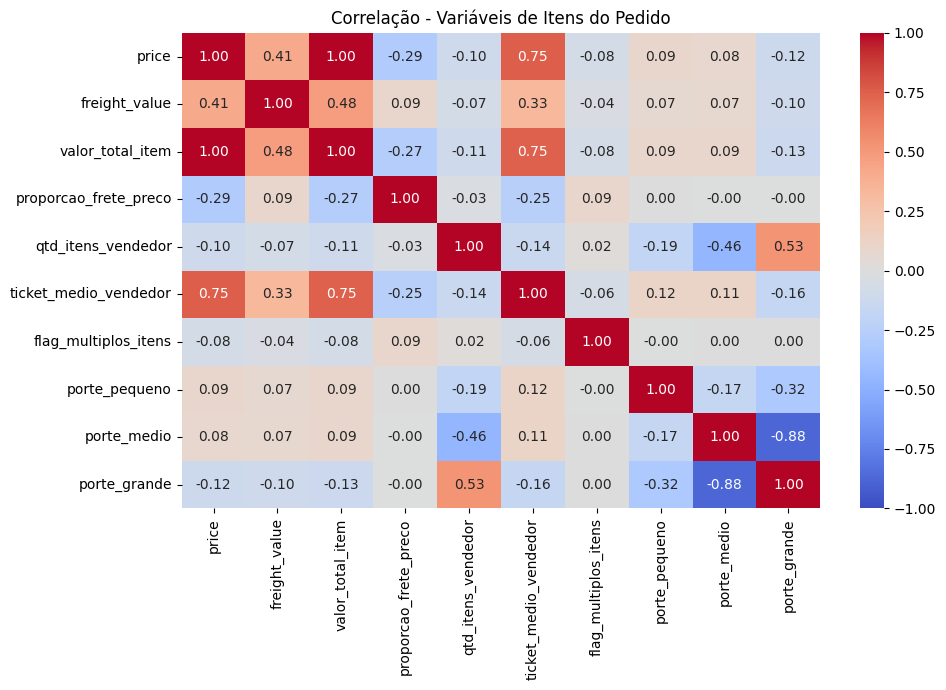

Colunas com variância <= 0.01: []
Shape antes: (112646, 26)
Shape depois: (112646, 23)
Colunas finais: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'proporcao_frete_preco', 'qtd_itens_vendedor', 'ticket_medio_vendedor', 'flag_multiplos_itens', 'porte_vendedor', 'porte_pequeno', 'porte_medio', 'porte_grande', 'price_minmax', 'price_zscore', 'freight_value_minmax', 'freight_value_zscore', 'proporcao_frete_preco_minmax', 'proporcao_frete_preco_zscore', 'qtd_itens_vendedor_minmax', 'qtd_itens_vendedor_zscore']


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import VarianceThreshold

cols_num = [
    "price",
    "freight_value",
    "valor_total_item",
    "proporcao_frete_preco",
    "qtd_itens_vendedor",
    "ticket_medio_vendedor",
    "flag_multiplos_itens",
    "porte_pequeno",
    "porte_medio",
    "porte_grande",
]

# 1. Heatmap de correlação das variáveis numéricas (sem as escalonadas)
plt.figure(figsize=(10, 7))
sns.heatmap(df_oid_f2[cols_num].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação - Variáveis de Itens do Pedido")
plt.tight_layout()
plt.show()

# 2. Verifica se há colunas com variância muito baixa (<= 0.01)
vt = VarianceThreshold(threshold=0.01)
vt.fit(df_oid_f2[cols_num])

baixa_variancia = [col for col, keep in zip(cols_num, vt.get_support()) if not keep]
print("Colunas com variância <= 0.01:", baixa_variancia)


# 3. Remove valor_total_item e suas escalas por ter correlação 1.00 (redundante) com price
def selecionar_atributos_order_items(df, cols_remover=None):
    out = df.copy()
    if cols_remover is None:
        cols_remover = [
            "valor_total_item",
            "valor_total_item_minmax",
            "valor_total_item_zscore",
        ]
    return out.drop(columns=cols_remover, errors="ignore")


print("Shape antes:", df_oid_f2.shape)
df_oid_sel = selecionar_atributos_order_items(df_oid_f2)
print("Shape depois:", df_oid_sel.shape)
print("Colunas finais:", list(df_oid_sel.columns))

**EXPLICAÇÃO**: O gráfico de calor mostrou que valor_total_item tinha correlação de 1,00 com price, funcionando de forma praticamente repetida na tabela. O teste de variação confirmou que nenhuma coluna possui variação baixa demais. Por isso, valor_total_item e suas duas colunas de escala foram removidas, reduzindo a tabela de 26 para 23 colunas e mantendo todos os 112.646 itens com os códigos de identificação, a data limite de despacho e as métricas principais dos vendedores.